Testing colour temperature throughout day

In [1]:
from utils.misc import (
    colourtemp_from_time, 
    lerp_color_temp,
    smoothstep_color_temp,
    legacy_get_colourtemp_for_time
)
from datetime import time
import matplotlib.pyplot as plt

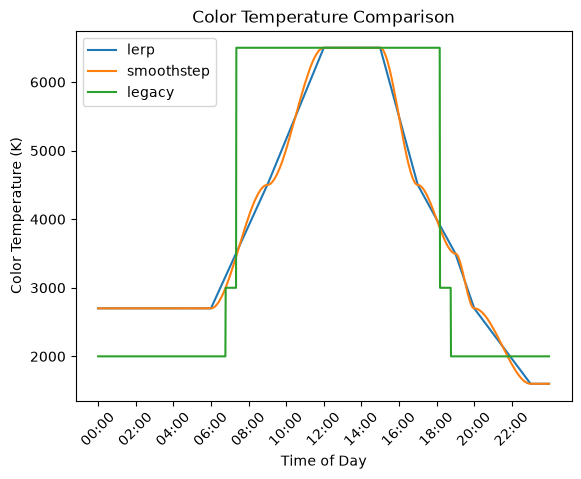

In [ ]:
def plot_colourtemp(func, func_name: str, ax: "plt.Axes") -> None: #type: ignore[reportPrivateImportUsage]
    col_temps: list[int] = []
    times: list[str] = []

    for i in range(24 * 60):
        hour, minute = divmod(i, 60)
        t = time(hour, minute)
        col_temps.append(colourtemp_from_time(t, func))
        times.append(f"{hour:02d}:{minute:02d}")

    ax.plot(times, col_temps, label=func_name)


fig, ax = plt.subplots()

plot_colourtemp(lerp_color_temp, "lerp", ax)
plot_colourtemp(smoothstep_color_temp, "smoothstep", ax)
plot_colourtemp(legacy_get_colourtemp_for_time, "legacy", ax)

tick_indices = range(0, 24 * 60, 120)
times_list = [f"{(i // 60):02d}:{(i % 60):02d}" for i in tick_indices]
ax.set_xticks(tick_indices)
ax.set_xticklabels(times_list)

for label in ax.get_xticklabels():
    label.set_rotation(45)

ax.set_xlabel("Time of Day")
ax.set_ylabel("Color Temperature (K)")
ax.set_title("Color Temperature Comparison")
ax.legend()

plt.show()

In [ ]:
import requests
from requests import status_codes
url = "http://raspberrypi.local:5000/config"
data = {"brightness": 0}
res = requests.post(url, json=data)

code:str = status_codes._codes[res.status_code][0]
print(res.status_code, code.replace("_", " "),"\n", res.text)

400 bad request 
 No valid config options provided
